<div align="center">

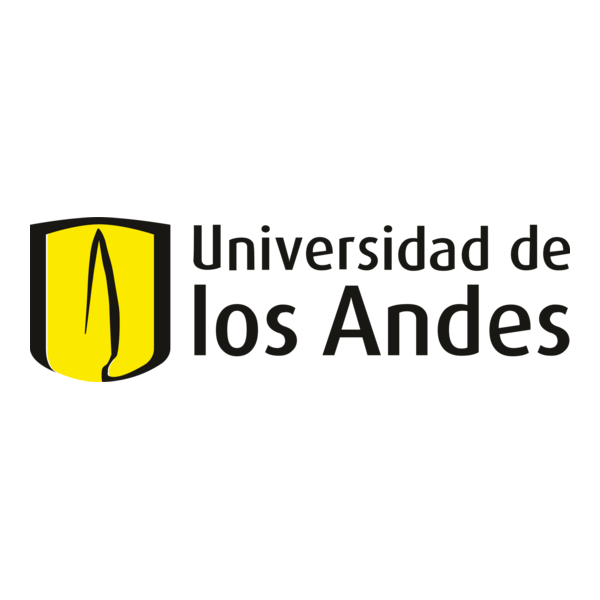

<h1>Proyecto de grado</h1>
<strong>Recuperación semántica y clasificación de la función de citas académicas en Computer Science</strong>
<p>Universidad de los Andes · Maestría en Inteligencia Artificial · Grupo 15</p>
<p>Sebastian Toro · Camilo Bejarano · German Rodriguez · Jose Arteaga</p>
</div>


En este notebook medimos cómo responden nuestros dos SciBERT a citas revisadas por
personas. Los modelos ya están seleccionados: uno recibe contexto, título y abstract;
el otro, contexto y tres fragmentos con sus secciones. Conservamos sus pesos y su
preparación del texto. Aquí no buscamos parámetros ni entrenamos otra vez.

## 1. Conocemos los datos que vamos a evaluar

Empezamos con el tamaño y la distribución del test humano. Comprobamos sus archivos
y que los documentos del test no estén en entrenamiento o validación. Los dos casos
sin categoría clara quedan reservados y fuera de las métricas. Las etiquetas humanas
se utilizan como referencia de evaluación, nunca como entrada para predecir.


Mounted at /content/drive


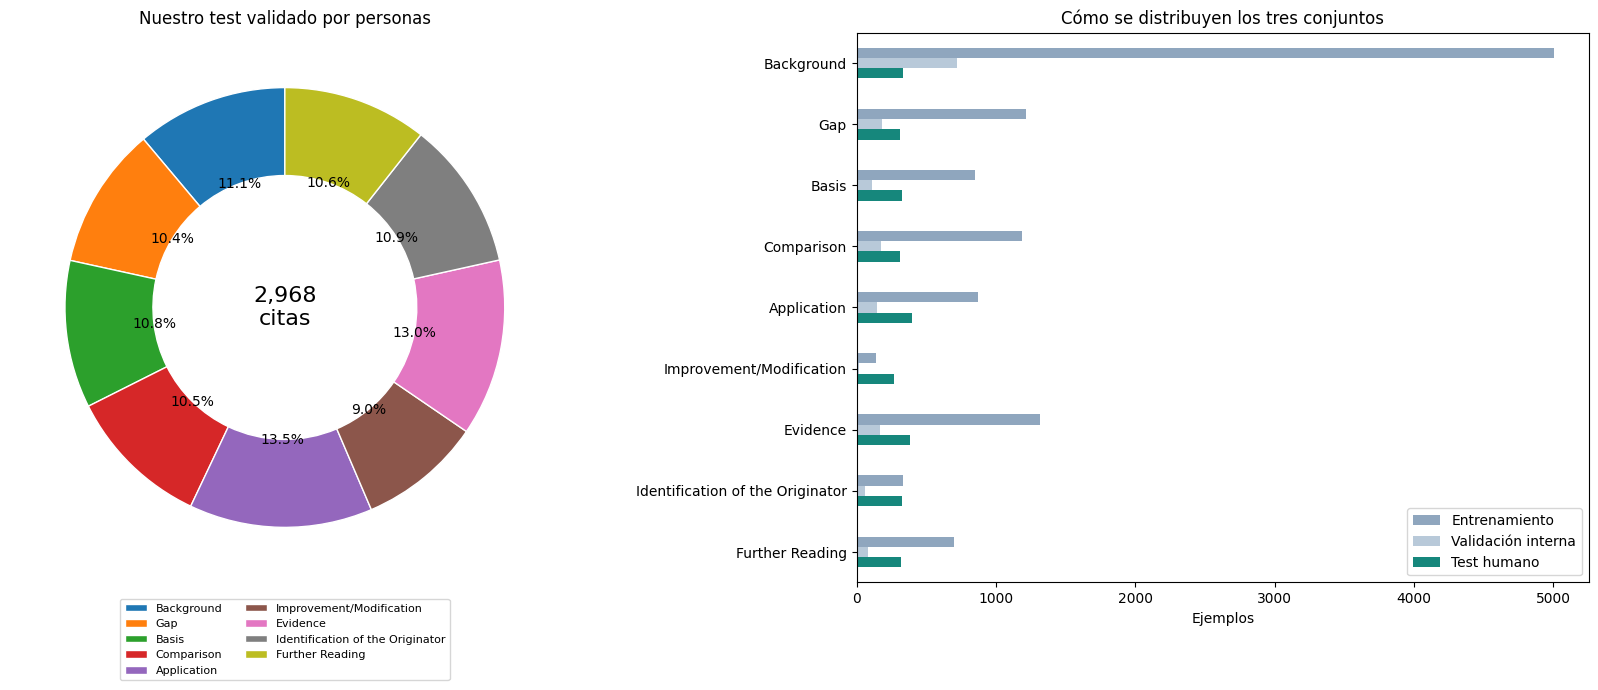

,Entrenamiento,Validación interna,Test humano
Background,5004,717,330
Gap,1217,179,310
Basis,848,112,322
Comparison,1188,176,313
Application,871,144,400
Improvement/Modification,140,19,268
Evidence,1318,166,386
Identification of the Originator,329,58,324
Further Reading,701,82,315


Evaluaremos 2,968 citas; dos casos sin categoría clara quedan excluidos del cálculo.


In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import sys
import subprocess
import importlib.metadata
from pathlib import Path
import torch
if not torch.cuda.is_available() or "A100" not in torch.cuda.get_device_name(0):
    raise RuntimeError("Conecta el notebook al servidor con la GPU requerida antes de continuar.")
if torch.__version__.split("+")[0] != "2.11.0":
    raise RuntimeError("Se requiere PyTorch 2.11.0 para conservar la versión de la evaluación anterior.")
PINNED = ["transformers==4.57.1","accelerate==1.11.0","scikit-learn==1.7.2",
          "matplotlib==3.10.7","safetensors==0.6.2","mlflow==3.17.2"]
installed = subprocess.run([sys.executable,"-m","pip","install","-q",*PINNED],capture_output=True,text=True)
if installed.returncode:
    raise RuntimeError("No se pudieron preparar las bibliotecas: "+installed.stderr[-1800:])
for requirement in PINNED:
    package,version=requirement.split("==")
    module="sklearn" if package=="scikit-learn" else package
    loaded=sys.modules.get(module)
    if loaded is not None and getattr(loaded,"__version__",version)!=version:
        raise RuntimeError("Reinicia este intérprete para cargar las versiones preparadas y vuelve a ejecutar desde el principio.")
torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32=False
torch.use_deterministic_algorithms(True)
from IPython.display import display,Markdown
"""Evaluación final de dos exportaciones congeladas. No contiene entrenamiento."""
import collections
import contextlib
import gc
import hashlib
import html
import importlib.util
import json
import math
import os
from pathlib import Path
import shutil
import sys
import time
import uuid

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def json_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False, allow_nan=False).encode()).hexdigest()


def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".partial_" + uuid.uuid4().hex)
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    os.replace(temporary, path)


def freeze_json(path, value):
    path = Path(path)
    if path.exists() and json.loads(path.read_text(encoding="utf-8")) != value:
        raise ValueError(f"Cambió el protocolo guardado en {path.name}; no se mezclarán resultados.")
    save_json(path, value)


def records(path):
    with Path(path).open(encoding="utf-8-sig") as stream:
        return [json.loads(line) for line in stream if line.strip()]


def verify_files(directory, hashes):
    directory = Path(directory).resolve()
    if not hashes:
        raise ValueError("Faltan huellas de los archivos.")
    for name, expected in hashes.items():
        path = (directory / name).resolve()
        if not path.is_relative_to(directory) or not path.is_file() or sha256(path) != expected:
            raise ValueError(f"Archivo ausente o distinto del esperado: {name}")


def keyed(rows):
    index = {}
    for row in rows:
        key = row["inst_key"]
        if key in index:
            raise ValueError(f"Instancia repetida: {key}")
        citing, _, _, cited = key.split("|")
        if citing != row["citing_paper_id"] or cited != row["cited_paper_id"] or citing == cited:
            raise ValueError("El identificador no corresponde a sus documentos.")
        index[key] = row
    return index


def document_set(rows):
    return {r[k] for r in rows for k in ["citing_paper_id", "cited_paper_id"]}


def verify_isolation(train, validation, reserved):
    sets = {"train": document_set(train), "validation": document_set(validation), "test": document_set(reserved)}
    for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
        if sets[left] & sets[right]:
            raise ValueError(f"Hay documentos compartidos entre {left} y {right}.")
    return {"passed": True, "documents": {k: len(v) for k, v in sets.items()}, "roles": "citing_and_cited"}


def prepare_test(study_root, a3_dir, old_ids_dir, pins, output):
    study_root, a3_dir, old_ids_dir, output = map(Path, [study_root, a3_dir, old_ids_dir, output])
    closed = json.loads((study_root / "STUDY_COMPLETE.json").read_text())
    if closed["study_id"] != pins["source_study_id"] or closed["test_scored"] is not False:
        raise ValueError("La selección no corresponde al estudio previo previsto.")
    verify_files(study_root, closed["report_hashes"])
    selected = json.loads((study_root / "selected_models.json").read_text())
    if selected["models"] != pins["models"] or selected["test_scored"] is not False:
        raise ValueError("Los modelos seleccionados cambiaron respecto de la selección congelada.")
    train_path, validation_path = [study_root / f"split_{name}_ids.jsonl" for name in ["train", "validation"]]
    for name, path in [("train", train_path), ("validation", validation_path)]:
        if sha256(path) != pins["split_hashes"][name]:
            raise ValueError("Cambió una partición de aprendizaje.")
    gold_path, metrics_path = a3_dir / "test_set_gold.jsonl", a3_dir / "manifest_metrics.json"
    ids_path = old_ids_dir / "test_set_ids_G15.jsonl"
    for path in [gold_path, metrics_path, ids_path]:
        if sha256(path) != pins["input_hashes"][path.name]:
            raise ValueError(f"La fuente humana o sus localizadores cambiaron: {path.name}")
    gold = records(gold_path)
    keyed(gold)
    own = [r for r in gold if r["set"] == "B"]
    if len(own) != 2970 or sum(r["in_eval"] is True for r in own) != 2968:
        raise ValueError("El test propio difiere del cierre humano congelado.")
    index = keyed(records(ids_path))
    reserved, test = [], []
    for human in own:
        source = index[human["inst_key"]]
        if human["in_eval"] is not (human["gold_primary"] in pins["labels"]):
            raise ValueError("La etiqueta y la marca de evaluación se contradicen.")
        row = {k: source[k] for k in ["inst_key", "citing_paper_id", "cited_paper_id", "source_batch"]}
        reserved.append(row)
        if human["in_eval"]:
            test.append({**row, "reference": human["gold_primary"]})
    train, validation = records(train_path), records(validation_path)
    keyed(train); keyed(validation); keyed(test)
    if (len(train), len(validation)) != (11616, 1653):
        raise ValueError("Los tamaños del aprendizaje no coinciden.")
    audit = verify_isolation(train, validation, reserved)
    test.sort(key=lambda r: r["inst_key"])
    counts = collections.Counter(r["reference"] for r in test)
    expected = dict(zip(pins["labels"], [330, 310, 322, 313, 400, 268, 386, 324, 315]))
    if dict(counts) != expected:
        raise ValueError("La distribución humana difiere del cierre revisado.")
    audit.update(valid_rows=len(test), unclear_excluded=2, reserved_rows=len(reserved),
        gold_sha256=sha256(gold_path), test_order_sha256=json_digest(test),
        split_hashes=pins["split_hashes"], source_closure_sha256=sha256(study_root / "STUDY_COMPLETE.json"))
    freeze_json(output / "data_audit.json", audit)
    pd.DataFrame(test).to_csv(output / "test_instances.csv", index=False)
    return test, train, validation, audit


def show_test_data(test, train, validation, labels, output):
    import matplotlib.pyplot as plt
    from IPython.display import display
    counts = pd.DataFrame({"Entrenamiento": collections.Counter(r["label"] for r in train),
        "Validación interna": collections.Counter(r["label"] for r in validation),
        "Test humano": collections.Counter(r["reference"] for r in test)}).reindex(labels).fillna(0).astype(int)
    counts.to_csv(Path(output) / "class_distribution.csv")
    fig, axes = plt.subplots(1, 2, figsize=(17, 7))
    wedges, _, _ = axes[0].pie(counts["Test humano"], startangle=90, autopct="%.1f%%",
        wedgeprops={"width": .4, "edgecolor": "white"})
    axes[0].text(0, 0, f"{len(test):,}\ncitas", ha="center", va="center", fontsize=16)
    axes[0].set_title("Nuestro test validado por personas")
    axes[0].legend(wedges, labels, loc="upper center", bbox_to_anchor=(.5, -.02), fontsize=8, ncol=2)
    counts.plot.barh(ax=axes[1], color=["#8fa6be", "#b8c9d9", "#16877c"])
    axes[1].invert_yaxis()
    axes[1].set(xlabel="Ejemplos", ylabel="", title="Cómo se distribuyen los tres conjuntos")
    fig.tight_layout()
    fig.savefig(Path(output) / "class_distribution.png", dpi=160, bbox_inches="tight")
    plt.show(); plt.close(fig)
    display(counts)
    print(f"Evaluaremos {len(test):,} citas; dos casos sin categoría clara quedan excluidos del cálculo.")
    return counts


def reconstruct_test(test, batch_dir, pins, output):
    texts, hashes = {}, {}
    required = {r["inst_key"]: r["source_batch"] for r in test}
    for batch in sorted(set(required.values())):
        path = Path(batch_dir) / (batch + ".jsonl")
        digest = sha256(path)
        if digest != pins["batch_hashes"].get(batch):
            raise ValueError(f"El lote no coincide con la preparación original: {batch}")
        hashes[batch] = digest
        seen = set()
        for raw in read_jsonl(path):
            key = raw["inst_key"]
            if key in seen:
                raise ValueError(f"Clave repetida en {batch}: {key}")
            seen.add(key)
            if required.get(key) == batch:
                texts[key] = normalize_batch(raw)
    if set(texts) != set(required):
        raise ValueError("No se reconstruyeron todas las entradas del test para ambos modelos.")
    audit = {"n": len(texts), "batch_hashes": hashes, "texts_sha256": json_digest(texts),
             "missing_sections": sum(ch["section_missing"] for r in texts.values() for ch in r["chunks"])}
    freeze_json(Path(output) / "reconstruction_audit.json", audit)
    return texts, audit


def model_payload(text, config):
    if config == "base":
        return {k: text[k] for k in ["context", "title", "abstract"]}
    if config == "fragmentos" and len(text["chunks"]) == 3:
        return {"context": text["context"], "chunks": [{k: c[k] for k in ["text", "section"]} for c in text["chunks"]]}
    raise ValueError("La configuración o el número de fragmentos no es válido.")


def show_examples(test, texts, output):
    from IPython.display import HTML, display
    examples = []
    for row in test[:2]:
        example = {"inst_key": row["inst_key"], "expected_human_label": row["reference"],
                   "base_input": model_payload(texts[row["inst_key"]], "base"),
                   "top3_input": model_payload(texts[row["inst_key"]], "fragmentos")}
        examples.append(example)
        blocks = [f"<h3>Ejemplo {len(examples)} · {html.escape(row['inst_key'])}</h3>",
                  f"<p><b>Referencia humana esperada:</b> {html.escape(row['reference'])}. Se usa para evaluar; no se envía al modelo.</p>"]
        for title, payload in [("Entrada de base", example["base_input"]), ("Entrada de Top-3", example["top3_input"])]:
            blocks.append(f"<details open><summary><b>{title}</b></summary><pre style='white-space:pre-wrap'>" +
                          html.escape(json.dumps(payload, ensure_ascii=False, indent=2)) + "</pre></details>")
        display(HTML("\n".join(blocks)))
    save_json(Path(output) / "two_real_examples.json", examples)


def load_validation_reference(study_root, pins, output):
    reference, reports = {}, {}
    for config, selected in pins["models"].items():
        trial = Path(study_root) / "trials" / selected["trial_id"]
        close = json.loads((trial / "EVALUATION_COMPLETE.json").read_text())
        verify_files(trial / "evaluation", close["files"])
        result = json.loads((trial / "evaluation/result.json").read_text())
        if result["trial_id"] != selected["trial_id"] or result["seed"] != 42 or result["n"] != 1653:
            raise ValueError("La referencia de validación no corresponde al modelo seleccionado.")
        trained=json.loads((trial/"TRAINING_COMPLETE.json").read_text())
        if (trained["model_hashes"] != selected["model_hashes"]
                or result["model_marker_sha256"] != sha256(trial/"TRAINING_COMPLETE.json")
                or not math.isclose(result["f1_macro"],selected["validation_fp32_f1_macro"],abs_tol=1e-12)):
            raise ValueError("El reporte de validación no está vinculado a la exportación seleccionada.")
        reference[config] = result
        reports[config] = json.loads((trial / "evaluation/classification_report.json").read_text())
    save_json(Path(output) / "validation_reference.json", {"results": reference, "reports": reports,
        "reference_type": "125 human and 1528 automatic labels; seed 42; not the three-seed mean"})
    return reference, reports


def verify_protocol(protocol):
    if (protocol["evaluation_policy"] != "fp32_eager" or protocol["batch_size"] != 32
            or protocol["models"].keys() != {"base", "fragmentos"} or protocol["test_count"] != 2968):
        raise ValueError("El protocolo final debe conservar las dos entradas y la evaluación prevista.")
    for config, spec in protocol["models"].items():
        if (spec["primary_seed"] != 42 or spec["context_budget"] != 192 or spec["loss_mode"] != "sin_pesos"
                or spec["learning_rate"] != 3e-5 or spec["weight_decay"] != .1):
            raise ValueError("Los modelos deben conservar la selección previa al test.")


def local_export(study_root, config, selected, cache_root):
    source = Path(study_root) / "trials" / selected["trial_id"] / "model"
    target = Path(cache_root) / config
    verify_files(source, selected["model_hashes"])
    target.mkdir(parents=True, exist_ok=True)
    for name, expected in selected["model_hashes"].items():
        dest = target / name
        if not dest.exists() or sha256(dest) != expected:
            dest.parent.mkdir(parents=True, exist_ok=True)
            temporary = dest.with_name(dest.name + ".partial_" + uuid.uuid4().hex)
            shutil.copyfile(source / name, temporary)
            if sha256(temporary) != expected:
                raise ValueError("La copia local del modelo no coincide.")
            os.replace(temporary, dest)
    verify_files(target, selected["model_hashes"])
    return target


def load_classifier(path, device):
    spec = importlib.util.spec_from_file_location("final_inference_" + uuid.uuid4().hex, Path(path) / "inference.py")
    module = importlib.util.module_from_spec(spec)
    previous = sys.dont_write_bytecode
    try:
        sys.dont_write_bytecode = True
        spec.loader.exec_module(module)
    finally:
        sys.dont_write_bytecode = previous
    classifier = module.CitationClassifier(path, device=device)
    classifier.model.float().eval()
    return module, classifier


def validate_prediction_frame(frame, expected_rows, labels, config):
    if len(frame) != len(expected_rows) or frame.inst_key.duplicated().any():
        raise ValueError("Las predicciones tienen filas ausentes o repetidas.")
    for row, expected in zip(frame.to_dict("records"), expected_rows):
        if any(row[k] != expected[k] for k in ["inst_key", "citing_paper_id", "cited_paper_id", "reference"]):
            raise ValueError("Las predicciones cambiaron de orden o referencia.")
        if row["config"] != config:
            raise ValueError("Se mezclaron modelos en las predicciones.")
    probabilities = frame[["score_" + label for label in labels]].to_numpy(float)
    if (not np.isfinite(probabilities).all() or (probabilities < 0).any() or (probabilities > 1).any()
            or not np.allclose(probabilities.sum(axis=1), 1, atol=1e-5)):
        raise ValueError("Probabilidades inválidas.")
    if not np.array_equal(np.asarray(labels)[probabilities.argmax(axis=1)], frame.pred_label.to_numpy()):
        raise ValueError("La categoría predicha no coincide con las probabilidades.")
    for column in ["latency_ms", "tokenization_ms", "inference_ms"]:
        values = frame[column].to_numpy(float)
        if not np.isfinite(values).all() or (values < 0).any():
            raise ValueError("La medición de tiempo no es válida.")


def read_part(path, receipt, expected, labels, config, protocol_hash):
    if not receipt.exists():
        return None
    marker = json.loads(receipt.read_text())
    if marker["protocol_sha256"] != protocol_hash or sha256(path) != marker["sha256"]:
        raise ValueError("Un lote guardado pertenece a otro protocolo o está dañado.")
    frame = pd.read_csv(path, dtype={"inst_key":str,"citing_paper_id":str,"cited_paper_id":str,
                                     "reference":str,"pred_label":str,"config":str})
    validate_prediction_frame(frame, expected, labels, config)
    return frame


def score_model(config, test, texts, protocol, study_root, cache_root, output, tracking, device="cuda"):
    import torch
    from transformers import DataCollatorWithPadding
    labels, size = protocol["labels"], protocol["batch_size"]
    protocol_hash = json_digest(protocol)
    directory = Path(output) / config
    parts = directory / "parts"
    parts.mkdir(parents=True, exist_ok=True)
    chunks = [test[start:start + size] for start in range(0, len(test), size)]
    cached = [read_part(parts / f"{i:05d}.csv", parts / f"{i:05d}.complete.json", rows, labels, config, protocol_hash)
              for i, rows in enumerate(chunks)]
    if all(frame is not None for frame in cached):
        print(config, ": todas las predicciones están verificadas; reutilizamos la inferencia.")
    with tracking.evaluation(config, directory, policy="test_gold_fp32") as run:
        tracking.client.set_tag(run, "reference", "human_gold_B")
        tracking.client.log_param(run, "protocol_sha256", protocol_hash)
        tracking.client.log_param(run, "trial_id", protocol["models"][config]["trial_id"])
        tracking.client.log_param(run, "latency_definition", "tokenization+forward; batch-average; warmup/IO excluded")
        tracking.backup(force=True)
        classifier = None
        try:
            if any(frame is None for frame in cached):
                path = local_export(study_root, config, protocol["models"][config], cache_root)
                module, classifier = load_classifier(path, device)
                mapping = {int(k): v for k, v in classifier.model.config.id2label.items()}
                if (mapping != dict(enumerate(labels)) or classifier.policy["config"] != config
                        or classifier.policy["context_budget"] != 192 or classifier.policy["max_length"] != 512
                        or classifier.model.config._attn_implementation != "eager"):
                    raise ValueError("La exportación cambió de categorías o preparación.")
                collator = DataCollatorWithPadding(classifier.tokenizer, pad_to_multiple_of=8)
                # Calentamiento sintético: no consulta etiquetas ni escoge modelos.
                warm = {"context": "We refer to [[TARGET]] for the method.", "title": "A scientific method",
                        "abstract": "A description of the scientific method.",
                        "chunks": [{"text": "A description of the scientific method.", "section": "Methods"}] * 3}
                feature, _ = module.encode_example(model_payload(warm, config), config, classifier.tokenizer, 512, 192)
                batch = {k: v.to(device) for k, v in collator([feature]).items()}
                with torch.inference_mode(), torch.autocast(device_type=torch.device(device).type, enabled=False):
                    classifier.model(**batch)
                if torch.device(device).type == "cuda": torch.cuda.synchronize()
            for i, rows in enumerate(chunks):
                if cached[i] is not None:
                    continue
                started = time.perf_counter()
                features, audits = [], []
                for row in rows:
                    feature, audit = module.encode_example(model_payload(texts[row["inst_key"]], config), config,
                                                           classifier.tokenizer, 512, 192)
                    features.append(feature); audits.append(audit)
                batch = {k: v.to(device) for k, v in collator(features).items()}
                if torch.device(device).type == "cuda": torch.cuda.synchronize()
                tokenization_ms = 1000 * (time.perf_counter() - started)
                started = time.perf_counter()
                with torch.inference_mode(), torch.autocast(device_type=torch.device(device).type, enabled=False):
                    probabilities = classifier.model(**batch).logits.float().softmax(-1).cpu().numpy()
                if torch.device(device).type == "cuda": torch.cuda.synchronize()
                inference_ms = 1000 * (time.perf_counter() - started)
                records_out = []
                for row, values, token_audit in zip(rows, probabilities, audits):
                    records_out.append({**row, "config": config, "measurement_run_id":str(run), "pred_label": labels[int(values.argmax())],
                        **{"score_" + label: float(p) for label, p in zip(labels, values)},
                        "latency_ms": (tokenization_ms + inference_ms) / len(rows),
                        "tokenization_ms": tokenization_ms / len(rows), "inference_ms": inference_ms / len(rows),
                        "total_tokens": token_audit["total_tokens"],
                        "context_truncated": token_audit["context_kept"] < token_audit["context_original"],
                        "evidence_truncated": token_audit["evidence_kept"] < token_audit["evidence_original"]})
                frame = pd.DataFrame(records_out)
                validate_prediction_frame(frame, rows, labels, config)
                path = parts / f"{i:05d}.csv"
                temporary = path.with_suffix(".partial.csv")
                frame.to_csv(temporary, index=False)
                os.replace(temporary, path)
                save_json(parts / f"{i:05d}.complete.json", {"sha256": sha256(path), "protocol_sha256": protocol_hash, "n": len(frame)})
                cached[i] = frame
                tracking.metrics(run, {"completed_examples": min((i + 1) * size, len(test))}, i + 1)
                tracking.backup()
                if i % 10 == 0 or i == len(chunks) - 1:
                    print(config, ":", min((i + 1) * size, len(test)), "/", len(test))
            predictions = pd.concat(cached, ignore_index=True)
            validate_prediction_frame(predictions, test, labels, config)
            predictions.to_csv(directory / "test_predictions.csv", index=False)
            save_json(directory / "PREDICTIONS_COMPLETE.json", {"n": len(predictions), "protocol_sha256": protocol_hash,
                "predictions_sha256": sha256(directory / "test_predictions.csv"), "latency_includes": "tokenization+host_to_device+forward+device_to_host",
                "latency_excludes": "model load, disk IO, initial warmup", "latency_unit": "batch average per example"})
            return predictions
        finally:
            if classifier is not None:
                del classifier
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()


def calculate_metrics(frame, labels):
    report = classification_report(frame.reference, frame.pred_label, labels=labels, output_dict=True, zero_division=0)
    result = {"n": len(frame), "accuracy": float((frame.reference == frame.pred_label).mean())}
    for average in ["macro", "micro"]:
        precision, recall, f1, _ = precision_recall_fscore_support(frame.reference, frame.pred_label,
            labels=labels, average=average, zero_division=0)
        result.update({f"precision_{average}": float(precision), f"recall_{average}": float(recall), f"f1_{average}": float(f1)})
    return result, report, confusion_matrix(frame.reference, frame.pred_label, labels=labels)


def plot_confusions(matrices, labels, output):
    import matplotlib.pyplot as plt
    short = ["BG", "Gap", "Basis", "Comp", "App", "I/M", "Evid", "Origin", "FR"]
    fig, axes = plt.subplots(2, 2, figsize=(16, 13))
    for column, (config, matrix) in enumerate(matrices.items()):
        normalized = np.divide(matrix, matrix.sum(axis=1, keepdims=True), out=np.zeros_like(matrix, dtype=float),
                               where=matrix.sum(axis=1, keepdims=True) != 0)
        for row, values in enumerate([matrix, normalized]):
            ax = axes[row, column]
            ax.imshow(values, cmap="Blues", vmin=0, vmax=matrix.max() if row == 0 else 1)
            ax.set(xticks=range(9), yticks=range(9), xticklabels=short, yticklabels=short,
                   xlabel="Predicción", ylabel="Referencia humana", title=f"{config}: " + ("conteos" if row == 0 else "% por clase real"))
            for i in range(9):
                for j in range(9):
                    ax.text(j, i, str(matrix[i,j]) if row == 0 else f"{100*values[i,j]:.0f}%", ha="center", va="center",
                            fontsize=8, color="white" if values[i,j] > values.max()/2 else "black")
    legend="BG: Background · Comp: Comparison · App: Application · I/M: Improvement/Modification\nEvid: Evidence · Origin: Identification of the Originator · FR: Further Reading"
    fig.text(.5,.01,legend,ha="center",fontsize=9)
    fig.tight_layout(rect=(0,.055,1,1))
    fig.savefig(Path(output) / "test_confusion_comparison.png", dpi=180)
    plt.show(); plt.close(fig)
    # Copias individuales para la entrega común.
    for config, matrix in matrices.items():
        fig, ax = plt.subplots(figsize=(10, 8))
        ax.imshow(matrix, cmap="Blues")
        ax.set(xticks=range(9), yticks=range(9), xticklabels=short, yticklabels=short,
               xlabel="Predicción", ylabel="Referencia humana", title=config)
        for i in range(9):
            for j in range(9):ax.text(j, i, str(matrix[i,j]), ha="center", va="center", fontsize=8)
        fig.tight_layout(); fig.savefig(Path(output) / config / "test_confusion.png", dpi=160); plt.close(fig)


def build_reports(predictions, test, train, validation_results, labels, output):
    import matplotlib.pyplot as plt
    from IPython.display import display
    output = Path(output)
    results, reports, matrices, per_class = {}, {}, {}, []
    before_after = []
    for config, frame in predictions.items():
        validate_prediction_frame(frame, test, labels, config)
        result, report, matrix = calculate_metrics(frame, labels)
        results[config], reports[config], matrices[config] = result, report, matrix
        folder = output / config
        folder.mkdir(exist_ok=True)
        save_json(folder / "test_classification_report.json", report)
        pd.DataFrame(matrix, index=labels, columns=labels).to_csv(folder / "test_confusion.csv")
        normalized=np.divide(matrix,matrix.sum(axis=1,keepdims=True),out=np.zeros_like(matrix,dtype=float),
                             where=matrix.sum(axis=1,keepdims=True)!=0)
        pd.DataFrame(normalized,index=labels,columns=labels).to_csv(folder/"test_confusion_normalized.csv")
        frame.loc[frame.reference != frame.pred_label].to_csv(folder / "test_errors.csv", index=False)
        per_class.extend({"config": config, "label": label, **report[label]} for label in labels)
        cited_in_train = {r["cited_paper_id"] for r in train}
        seen = frame.cited_paper_id.isin(cited_in_train)
        group_results = {}
        for name, mask in [("seen_as_cited_in_train", seen), ("unseen_as_cited_in_train", ~seen)]:
            group_results[name] = calculate_metrics(frame.loc[mask], labels)[0] if mask.any() else {"n": 0, "f1_macro": None}
        save_json(folder / "test_cited_seen_unseen.json", group_results)
        for split, source in [("Validación interna · 125 humanas / 1.528 automáticas", validation_results[config]),
                              ("Test · referencias humanas", result)]:
            before_after.append({"config": config, "conjunto": split, **{k: source[k] for k in result}})
    comparison = pd.DataFrame([{"config": config, **r} for config, r in results.items()])
    comparison.to_csv(output / "test_comparison.csv", index=False)
    per_class = pd.DataFrame(per_class)
    per_class.to_csv(output / "test_per_class.csv", index=False)
    before_after = pd.DataFrame(before_after)
    before_after.to_csv(output / "validation_vs_test.csv", index=False)
    latency = [{"config":config,"n":len(frame),"mean_ms":float(frame.latency_ms.mean()),
                "median_ms":float(frame.latency_ms.median()),"p95_ms":float(frame.latency_ms.quantile(.95)),
                "measurement_sessions":int(frame.measurement_run_id.nunique()),
                "definition":"batch_average_per_example; not individually timed requests"}
               for config,frame in predictions.items()]
    pd.DataFrame(latency).to_csv(output/"latency_summary.csv",index=False)
    display(comparison); display(per_class); display(before_after)
    plot_confusions(matrices, labels, output)
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    comparison.set_index("config")[["precision_macro", "recall_macro", "f1_macro"]].plot.bar(ax=axes[0], ylim=(0,1), rot=0)
    axes[0].set(title="Comparación sobre el mismo test humano", ylabel="Puntuación", xlabel="")
    per_class.pivot(index="label", columns="config", values="f1-score").reindex(labels).plot.barh(ax=axes[1], xlim=(0,1))
    axes[1].invert_yaxis(); axes[1].set(title="F1 por categoría", xlabel="F1", ylabel="")
    fig.tight_layout(); fig.savefig(output / "test_metrics_comparison.png", dpi=160); plt.show(); plt.close(fig)
    fig, ax = plt.subplots(figsize=(11,5))
    before_after.pivot(index="config", columns="conjunto", values="f1_macro").plot.bar(ax=ax, ylim=(0,1), rot=0)
    ax.set(title="Validación interna frente a test humano · mismos modelos, distintos conjuntos", ylabel="F1 macro", xlabel="")
    fig.tight_layout(); fig.savefig(output / "validation_vs_test.png", dpi=160); plt.show(); plt.close(fig)
    print("La diferencia entre conjuntos no demuestra una mejora o deterioro del modelo: cambian las citas y sus referencias.")
    return results, reports


def macro_from_cm(cm):
    cm = np.asarray(cm, dtype=float)
    tp = np.diagonal(cm, axis1=-2, axis2=-1)
    denominator = cm.sum(axis=-1) + cm.sum(axis=-2)
    return np.divide(2*tp, denominator, out=np.zeros_like(tp), where=denominator != 0).mean(axis=-1)


def paired_bootstrap(base, top3, labels, repetitions=2000, seed=20261113):
    keys = ["inst_key", "citing_paper_id", "reference"]
    if len(base) == 0 or not base[keys].equals(top3[keys]) or base.inst_key.duplicated().any():
        raise ValueError("El bootstrap requiere las mismas instancias y referencias, en el mismo orden.")
    if repetitions < 100:
        raise ValueError("Se requieren al menos 100 remuestreos.")
    groups, inverse = np.unique(base.citing_paper_id.to_numpy(), return_inverse=True)
    label_ids = {label: i for i, label in enumerate(labels)}
    true = base.reference.map(label_ids).to_numpy()
    if pd.isna(true).any(): raise ValueError("Referencia desconocida.")
    matrices = []
    for frame in [base, top3]:
        pred = frame.pred_label.map(label_ids).to_numpy()
        if pd.isna(pred).any(): raise ValueError("Predicción desconocida.")
        cm = np.zeros((len(groups), len(labels), len(labels)), dtype=np.int64)
        np.add.at(cm, (inverse, true, pred), 1)
        matrices.append(cm)
    rng, deltas = np.random.default_rng(seed), []
    for _ in range(repetitions):
        counts = rng.multinomial(len(groups), np.full(len(groups), 1/len(groups)))
        sampled = [np.tensordot(counts, cm, axes=(0,0)) for cm in matrices]
        deltas.append(float(macro_from_cm(sampled[1]) - macro_from_cm(sampled[0])))
    lo, hi = np.quantile(deltas, [.025,.975])
    return {"difference": "Top-3 minus base", "metric":"f1_macro", "delta":float(macro_from_cm(matrices[1].sum(0))-macro_from_cm(matrices[0].sum(0))),
        "ci95_percentile":[float(lo),float(hi)], "bootstrap_unit":"citing_paper_id", "n_groups":len(groups),
        "n_instances":len(base), "repetitions":repetitions, "seed":seed, "fixed_labels":labels}, np.asarray(deltas)


def show_paired_and_errors(predictions, labels, texts, output, repetitions=2000, seed=20261113):
    import matplotlib.pyplot as plt
    from IPython.display import display
    result, deltas = paired_bootstrap(predictions["base"], predictions["fragmentos"], labels, repetitions, seed)
    save_json(Path(output) / "paired_test_comparison.json", result)
    pd.DataFrame({"delta_f1_macro":deltas}).to_csv(Path(output) / "bootstrap_deltas.csv", index=False)
    fig, ax = plt.subplots(figsize=(9,4))
    ax.hist(100*deltas, bins=40, color="#16877c")
    ax.axvline(0, color="black", linestyle="--")
    for endpoint in result["ci95_percentile"]:ax.axvline(100*endpoint,color="#c76c35")
    ax.set(title="Diferencia Top-3 − base · bootstrap por artículo citante", xlabel="Diferencia de F1 macro (puntos porcentuales)",ylabel="Remuestreos")
    fig.tight_layout(); fig.savefig(Path(output)/"paired_test_comparison.png",dpi=160); plt.show(); plt.close(fig)
    merged = predictions["base"][["inst_key","reference","pred_label"]].rename(columns={"pred_label":"base_prediction"}).merge(
        predictions["fragmentos"][["inst_key","pred_label"]].rename(columns={"pred_label":"top3_prediction"}),on="inst_key",validate="one_to_one")
    merged["disagree"] = merged.base_prediction != merged.top3_prediction
    errors = merged.loc[(merged.reference != merged.base_prediction) | (merged.reference != merged.top3_prediction)]
    counts = collections.Counter((r.reference,p) for r in errors.itertuples() for p in [r.base_prediction,r.top3_prediction] if p != r.reference)
    chosen = []
    for (reference,predicted),count in sorted(counts.items(),key=lambda item:(-item[1],item[0])):
        candidates = errors.loc[(errors.reference==reference)&((errors.base_prediction==predicted)|(errors.top3_prediction==predicted))].sort_values("inst_key")
        for row in candidates.to_dict("records"):
            if row["inst_key"] not in {r["inst_key"] for r in chosen}:
                chosen.append({**row,"frequent_confusion":f"{reference} → {predicted}","confusion_count_across_models":count,
                    "context_excerpt":texts[row["inst_key"]]["context"][:400]})
                break
        if len(chosen)==2:break
    save_json(Path(output)/"error_examples.json",chosen)
    pd.DataFrame(chosen).to_csv(Path(output)/"error_examples.csv",index=False)
    display(pd.DataFrame(chosen)); display(pd.DataFrame([result]))
    print("Los ejemplos muestran errores reales frecuentes. Sus causas requieren lectura; no se asignan explicaciones automáticas.")
    return result


def final_conclusions(results, reports, paired, validation_results):
    base, top = results["base"], results["fragmentos"]
    lo, hi = (100*v for v in paired["ci95_percentile"])
    if lo > 0: interpretation="El intervalo favorece a Top-3 en este test."
    elif hi < 0: interpretation="El intervalo favorece a base en este test."
    else: interpretation="El intervalo incluye cero; no establece una ventaja clara de una entrada sobre la otra."
    first=(f"Evaluamos los dos modelos congelados sobre **{base['n']:,} citas con referencia humana**. "
        f"Base obtuvo F1 macro **{base['f1_macro']:.4f}** y micro **{base['f1_micro']:.4f}**; "
        f"Top-3 obtuvo **{top['f1_macro']:.4f}** y **{top['f1_micro']:.4f}**, respectivamente. "
        f"La diferencia Top-3 − base fue **{100*paired['delta']:+.2f} puntos porcentuales**, con IC 95 % "
        f"por bootstrap pareado por artículo citante **[{lo:+.2f}; {hi:+.2f}]**. {interpretation}")
    label="Improvement/Modification"
    second=(f"En {label}, con {int(reports['base'][label]['support'])} ejemplos de test, "
        f"el F1 fue **{reports['base'][label]['f1-score']:.4f}** para base y **{reports['fragmentos'][label]['f1-score']:.4f}** "
        "para Top-3. Las matrices y los reportes permiten distinguir las confusiones por categoría. "
        "Esta clase tuvo solo 140 ejemplos de entrenamiento; su resultado no elimina la limitación de representación.")
    third=(f"Los mismos modelos habían obtenido F1 macro de validación interna "
        f"{validation_results['base']['f1_macro']:.4f} y {validation_results['fragmentos']['f1_macro']:.4f}. "
        "Esa validación tenía 125 etiquetas humanas y 1.528 automáticas: la diferencia con el test no demuestra "
        "por sí sola una mejora o deterioro. Conservamos los modelos, el recorte a 512 tokens y la separación por documento; "
        "el test no se utilizó para ajustar parámetros. Los resultados se limitan al conjunto evaluado y sus criterios de selección.")
    return "\n\n".join([first,second,third])+"\n"

def acquire_experiment_writer(root):
    import fcntl
    import os
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    locks = globals().setdefault("_EXPERIMENT_WRITER_LOCKS", {})
    key = str(root.resolve())
    if key in locks and not locks[key].closed:
        return locks[key]
    handle = (root / "writer.lock").open("a+")
    try:
        fcntl.flock(handle, fcntl.LOCK_EX | fcntl.LOCK_NB)
    except BlockingIOError:
        handle.close()
        raise RuntimeError("Otra sesión está escribiendo este experimento. Recupera esa sesión antes de continuar.")
    handle.seek(0)
    handle.truncate()
    handle.write(str(os.getpid()))
    handle.flush()
    locks[key] = handle
    return handle

def release_experiment_writer(root):
    import fcntl
    handle = globals().get("_EXPERIMENT_WRITER_LOCKS", {}).pop(str(Path(root).resolve()), None)
    if handle is not None and not handle.closed:
        fcntl.flock(handle, fcntl.LOCK_UN)
        handle.close()
PINS = {'source_study_id': 'g15_scibert_reparto_v2_01', 'source_folder': 'g15_scibert_reparto_v2_01', 'model_id': 'allenai/scibert_scivocab_uncased', 'model_revision': '24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1', 'labels': ['Background', 'Gap', 'Basis', 'Comparison', 'Application', 'Improvement/Modification', 'Evidence', 'Identification of the Originator', 'Further Reading'], 'split_hashes': {'train': '7636b0a0a2704c9e04a22cbb6ad9140b9fc65dc5bb8f5761f6a8b141d2fe5a02', 'validation': 'f7b544a3f787f5a40f101f57ac4662ad49e27a9296dfdd19e5d67b50afc7223f'}, 'input_hashes': {'manifest_training_v2_G15.json': 'c7dd23f92b2272338a9d98dec7cf86476937658aa09a8cd3706c9402be34e231', 'manifest_metrics.json': '30118fea362fc4c0389ab34e2460d566d886d5dd7f11e8a84483b62b98a7ce5b', 'training_v2_G15.jsonl': 'a7a2039669573a7e42b8eff2629234f100f7270371245b44777fe5a075f1a1b4', 'exclusion_list_G15_V0_v2.jsonl': '0dfa8d69ede8e81c60f509643544eb748bd697b54da707f9ad9bd15a68489f15', 'exclusion_list_G15_V1_v2.jsonl': 'c05d4bb17c2a862ae48d2af920fbd6bfd79bdfae182ffd607bffe9d610361452', 'exclusion_list_G15_V2_v2.jsonl': '1b4d56acad06ed561ecc016997a595540d790df16ab4738df6ae22998118f0c6', 'test_set_gold.jsonl': '3b39f7d2eb42a47a46810b590e9ec40d0bb562c00c0c1eb958921978599af57d', 'manifest_training_v1_G15.json': 'b166f003062c95cba8a26826e5ea34f39268aef746f1ac1b6d5f9f2e3a348ad9', 'training_v1_G15.jsonl': 'b5019d58bb631360826dfce7389e321747abf04ff4d33d777dfba9c158bddf5b', 'test_set_ids_G15.jsonl': '96513833027ac30333c7a818fb56080062f6590f4993b3c515f2391f73bc43c7', 'pilot_random_1500.jsonl': '6ec2511d1d7d354396cd082f5dcb7325ffc33a840bd50b0b32b3a92ad637ce43', 'pool_cue_basis.jsonl': '0dadc2022f71e8b569c27583e2b7a6c3f9b181d997134133571742e4194deba2', 'pool_cue_cmp.jsonl': '64e3fe248f6c72acffb78d1670f80b808cf2be2b50a11c5cfed5144570b016ae', 'pool_cue_eg.jsonl': '49c3640e878b73e44a6a7221409fc77afc5649211ce09f581cf95cb48e0624f0', 'pool_cue_rare.jsonl': 'f8a768d7bc15c732097ef712ec4ec3900aa1cf3149c7cefecdb3f384f28e522b', 'pool_cue_yield.jsonl': '0b9a3cfbca8810b4533c0630b5ae97415bc5eb4d4de470e660cd696ec0192a0d', 'pool_ext_cue_rare.jsonl': '243e0222dfd043141d9ac8bdf3e85be5817d27e6699bc64f4dfa2a9600a47428', 'pool_single_7000.jsonl': 'c5cf38cc818c5e785a928a57b2d7535e130ad90aa72fa726f2b7c13cedc6e8e3'}, 'batch_hashes': {'pilot_random_1500': '6ec2511d1d7d354396cd082f5dcb7325ffc33a840bd50b0b32b3a92ad637ce43', 'pool_cue_basis': '0dadc2022f71e8b569c27583e2b7a6c3f9b181d997134133571742e4194deba2', 'pool_cue_cmp': '64e3fe248f6c72acffb78d1670f80b808cf2be2b50a11c5cfed5144570b016ae', 'pool_cue_eg': '49c3640e878b73e44a6a7221409fc77afc5649211ce09f581cf95cb48e0624f0', 'pool_cue_rare': 'f8a768d7bc15c732097ef712ec4ec3900aa1cf3149c7cefecdb3f384f28e522b', 'pool_cue_yield': '0b9a3cfbca8810b4533c0630b5ae97415bc5eb4d4de470e660cd696ec0192a0d', 'pool_ext_cue_rare': '243e0222dfd043141d9ac8bdf3e85be5817d27e6699bc64f4dfa2a9600a47428', 'pool_single_7000': 'c5cf38cc818c5e785a928a57b2d7535e130ad90aa72fa726f2b7c13cedc6e8e3'}, 'models': {'base': {'trial_id': 'grid_base_contexto_192_lr3em05_wd0p1_s42', 'primary_seed': 42, 'model_dir': '/content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_reparto_v2_01/trials/grid_base_contexto_192_lr3em05_wd0p1_s42/model', 'model_hashes': {'added_tokens.json': '00d0183e3bc9d9465928e54c9422d5b474d0f2e788b656eeced46ef704a1dca9', 'api_contract.json': '3c0f3e5d9ca1166333a08ee144f63a9102a7a7625b910f436a4f1a560027648a', 'config.json': 'e26fdb72cc8a7c2953d4fddf1a3937e54bd6b7c70197a1208a392b5996480bb9', 'inference.py': 'd83e3ccf8145a1a898a83c19d19b01b310a0c538065bec863c4a1b9b098ada75', 'input_policy.json': '8a8e552823d93cd0ace54a5afde1904fa63154cb6e04726ffbff4896432aabcf', 'label_mapping.json': '17df253d8087c710b620f37310c0667863cd53773b09260932847e8f0203db3c', 'model.safetensors': '985b9ee61228618e37d2883fdfa004c2f47d5d5628c8668c9187771d8a98ade4', 'run_manifest.json': '9dbf6c6f9d22222698571f9c9efd11c16c925e2dff1f46a8a5efdf0687e772a3', 'special_tokens_map.json': '42aee9d4e017e241a3ad6a734066fc6274f2c8d9052834c004881feccad53cd4', 'tokenizer.json': 'a3be493f335b67bb37a5b4d85e5ce1e7beede0ae7a226b77f57d21c942fd5d4e', 'tokenizer_config.json': 'b44f77b1f4cf5bf47da59bd1b5fe41ae70fef637e3760bc059486933f2740a9e', 'training_args.bin': 'e66a97b13ceedd4e04d8959030c11a250af0332dba07ee68598825856f74e520', 'training_objective.json': '44fcf623f366114d38c4b55545192411bcb691d37b4c03b34df7a88f0c8260d7', 'vocab.txt': 'f0a650346e51ede8996710f79ba65d83fdb8da05b159f17037b74ba4e3a36c6f'}, 'archive': '/content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_reparto_v2_01/scibert_base_final.zip', 'archive_sha256': '9558dfa1cbac371bb8a7242a54fd7c6cf4d9b4ed54c8d9947140ad4f2f752a3e', 'condition': 'contexto_192', 'context_budget': 192, 'loss_mode': 'sin_pesos', 'class_weights': [1, 1, 1, 1, 1, 1, 1, 1, 1], 'learning_rate': 3e-05, 'weight_decay': 0.1, 'best_epoch': 5, 'validation_fp32_f1_macro': 0.8302984472004021}, 'fragmentos': {'trial_id': 'grid_fragmentos_contexto_192_lr3em05_wd0p1_s42', 'primary_seed': 42, 'model_dir': '/content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_reparto_v2_01/trials/grid_fragmentos_contexto_192_lr3em05_wd0p1_s42/model', 'model_hashes': {'added_tokens.json': '00d0183e3bc9d9465928e54c9422d5b474d0f2e788b656eeced46ef704a1dca9', 'api_contract.json': 'f69f96f00bf1e37dff65acfefcd0c272dc11420b09c789b042e727f37fce5daa', 'config.json': 'e26fdb72cc8a7c2953d4fddf1a3937e54bd6b7c70197a1208a392b5996480bb9', 'inference.py': 'd83e3ccf8145a1a898a83c19d19b01b310a0c538065bec863c4a1b9b098ada75', 'input_policy.json': '1d85a041deea9e411b7f6e32bb650e3d630ab4f85e506b8f4597968f8cc438e9', 'label_mapping.json': '17df253d8087c710b620f37310c0667863cd53773b09260932847e8f0203db3c', 'model.safetensors': '19c8ddb575e24aa043c934c6206639362f3605041a7f5806ec851e0da1f637d7', 'run_manifest.json': '12b5b5c16de7cdeb4d23fb1669ad569818edd35936622d3cb179ab5f595a1616', 'special_tokens_map.json': '42aee9d4e017e241a3ad6a734066fc6274f2c8d9052834c004881feccad53cd4', 'tokenizer.json': 'a3be493f335b67bb37a5b4d85e5ce1e7beede0ae7a226b77f57d21c942fd5d4e', 'tokenizer_config.json': 'b44f77b1f4cf5bf47da59bd1b5fe41ae70fef637e3760bc059486933f2740a9e', 'training_args.bin': '696962da9391b8cb30c8ac2a85928523bd48be43e174f2053946719a96a8b010', 'training_objective.json': '44fcf623f366114d38c4b55545192411bcb691d37b4c03b34df7a88f0c8260d7', 'vocab.txt': 'f0a650346e51ede8996710f79ba65d83fdb8da05b159f17037b74ba4e3a36c6f'}, 'archive': '/content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_reparto_v2_01/scibert_fragmentos_final.zip', 'archive_sha256': '50fe9705a7a89c6a5c7d0316d88a81ce36356298454656e38541b74bbd7f8087', 'condition': 'contexto_192', 'context_budget': 192, 'loss_mode': 'sin_pesos', 'class_weights': [1, 1, 1, 1, 1, 1, 1, 1, 1], 'learning_rate': 3e-05, 'weight_decay': 0.1, 'best_epoch': 7, 'validation_fp32_f1_macro': 0.8300708310716729}}}

DATA_ROOT = Path("/content/drive/MyDrive/MAIA_PROYECTO")
RESULTS_ROOT = Path("/content/drive/MyDrive/MAIA_TESIS")
if not DATA_ROOT.is_dir() or not RESULTS_ROOT.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")
if not DATA_ROOT.is_dir() or not RESULTS_ROOT.is_dir():
    raise FileNotFoundError("Revisa los accesos a MAIA_PROYECTO y MAIA_TESIS.")
RUN_ID = "g15_scibert_test_B_final_01"
STUDY_ROOT = RESULTS_ROOT/"a4"/PINS["source_folder"]
OUTPUT_ROOT = RESULTS_ROOT/"a4"/RUN_ID
TRACKING_ROOT = Path("/opt/maia/a4_tracking_final_test")
CACHE_ROOT = Path("/content/maia_final_test_models")
acquire_experiment_writer(TRACKING_ROOT)
OUTPUT_ROOT.mkdir(parents=True,exist_ok=True)
test_rows,train_rows,validation_rows,data_audit = prepare_test(STUDY_ROOT,DATA_ROOT/"a3",
    RESULTS_ROOT/"TrainingData_Grupo15",PINS,OUTPUT_ROOT)
counts = show_test_data(test_rows,train_rows,validation_rows,PINS["labels"],OUTPUT_ROOT)


## 2. Vemos dos ejemplos reales antes de pedir predicciones

Reconstruimos todas las entradas desde los mismos lotes de texto del trabajo previo.
Mostramos las dos primeras citas en el orden fijo de identificadores: no son casos
elegidos por sus aciertos. Cada una incluye el contexto, título, abstract, los tres
fragmentos y sus secciones, además de la referencia humana esperada. En los bloques
de entrada se ve exactamente qué campos recibe cada modelo, sin la etiqueta.


In [2]:
BATCH_FIELDS = {"inst_key":"inst_key","context":"context","title":"cited_title","abstract":"cited_abstract","chunks":"top3"}
CHUNK_FIELDS = {"text":"text","section":"section"}
def read_jsonl(path):
    with Path(path).open(encoding="utf-8-sig") as f:
        for n, line in enumerate(f, 1):
            if line.strip():
                try:
                    row = json.loads(line)
                except json.JSONDecodeError as e:
                    raise ValueError(f"JSON inválido: {path}:{n}") from e
                if not isinstance(row, dict):
                    raise ValueError(f"Se esperaba un objeto: {path}:{n}")
                yield row

def field_at(row, dotted):
    value = row
    for part in dotted.split("."):
        if not isinstance(value, dict) or part not in value:
            raise KeyError(f"Campo '{dotted}' ausente. Ajusta el adaptador con el esquema real.")
        value = value[part]
    return value

def require_text(value, name):
    if not isinstance(value, str) or not value.strip():
        raise ValueError(f"Texto vacío o tipo incorrecto: {name}")
    return value.strip()

def normalize_batch(row):
    out = {k: require_text(field_at(row, BATCH_FIELDS[k]), k)
           for k in ("inst_key", "context", "title", "abstract")}
    if out["context"].count("[[TARGET]]") != 1:
        raise ValueError(f"Se requiere un [[TARGET]] por contexto: {out['inst_key']}")
    if "{{cite:" in out["context"]:
        raise ValueError("Quedan marcadores crudos. Usa el renderizador congelado de A2.")
    raw_chunks = field_at(row, BATCH_FIELDS["chunks"])
    if not isinstance(raw_chunks, list) or len(raw_chunks) != 3:
        raise ValueError(f"Top-3 incompleto: {out['inst_key']}")
    out["chunks"] = []
    for ch in raw_chunks:
        text = require_text(field_at(ch, CHUNK_FIELDS["text"]), "chunk.text")
        section = field_at(ch, CHUNK_FIELDS["section"])
        if section is not None and not isinstance(section, str):
            raise ValueError(f"Tipo incorrecto de sección: {out['inst_key']}")
        missing_section = section is None or not section.strip()
        out["chunks"].append({"text": text, "section": "Unknown" if missing_section else section.strip(),
                              "section_missing": missing_section})
    return out
texts,reconstruction_audit = reconstruct_test(test_rows,DATA_ROOT/"a2/batches_norw",PINS,OUTPUT_ROOT)
show_examples(test_rows,texts,OUTPUT_ROOT)


## 3. Identificamos los dos modelos que ya seleccionamos

Usamos los modelos principales de la semilla 42 del estudio de reparto, con contexto
de hasta 192 tokens y pérdida sin pesos. Los dos tienen LR 3e-5 y regularización 0,1;
sus mejores épocas fueron 5 (base) y 7 (Top-3). El máximo de entrada sigue siendo 512
tokens incluyendo separadores. Evaluamos en FP32 y con la misma atención de la
evaluación anterior. Cargaremos un modelo a la vez.

También recuperamos sus reportes de validación de la semilla 42. Esas cifras no son
la media de tres semillas y no se mezclarán con ella en la comparación «antes y ahora».


In [3]:
validation_results,validation_reports = load_validation_reference(STUDY_ROOT,PINS,OUTPUT_ROOT)
display(pd.DataFrame([{ "modelo":c,"ensayo":m["trial_id"],"semilla":m["primary_seed"],
    "contexto_máximo":m["context_budget"],"mejor_época":m["best_epoch"],
    "F1_validación_semilla_42":validation_results[c]["f1_macro"],
    "SHA256_pesos":m["model_hashes"]["model.safetensors"]} for c,m in PINS["models"].items()]))


,modelo,ensayo,semilla,contexto_máximo,mejor_época,F1_validación_semilla_42,SHA256_pesos
0,base,grid_base_contexto_192_lr3em05_wd0p1_s42,42,192,5,0.830298,985b9ee61228618e37d2883fdfa004c2f47d5d5628c866...
1,fragmentos,grid_fragmentos_contexto_192_lr3em05_wd0p1_s42,42,192,7,0.830071,19c8ddb575e24aa043c934c6206639362f3605041a7f58...


## 4. Fijamos el protocolo y guardamos el historial

Dejamos registrados modelos, datos, preparación, versiones y métricas antes de
calcular las predicciones. Los dos modelos reciben las mismas citas y se evalúan
con lotes de 32. El test no decide parámetros. Si cambiara esta configuración, el
notebook se detendría para evitar mezclar resultados.

Los lotes terminados se verifican y se recuperan después de una interrupción.
MLflow guarda un estudio nuevo, separado de los entrenamientos, con respaldos
propios. Ejecutamos una sola sesión de este notebook a la vez.


In [4]:
import datetime as dt
import numbers
import sqlite3
import tempfile
import zipfile
from pathlib import PurePosixPath
import mlflow
from mlflow import MlflowClient
def tracking_restore(root, snapshots):
    """Solo restaura antes de abrir MLflow; nunca sobrescribe una DB local."""
    root.mkdir(parents=True, exist_ok=True)
    if (root / "mlflow.db").exists():
        return
    candidates = sorted((p.parent for p in snapshots.glob("*/COMPLETE.json")),
        key=lambda p: dt.datetime.fromisoformat(json.loads((p / "COMPLETE.json").read_text())["created_at_utc"]))
    if not candidates:
        print("Sin historial previo: se creará una base MLflow nueva.")
        return
    source = candidates[-1]
    receipt = json.loads((source / "COMPLETE.json").read_text())
    archive_path = source / "snapshot.zip"
    assert receipt["schema_version"] == 1
    assert receipt["snapshot_id"] == source.name
    assert receipt["mlflow_version"] == mlflow.__version__
    assert archive_path.stat().st_size == receipt["zip_size"]
    assert sha256(archive_path) == receipt["zip_sha256"]
    assert (source / "snapshot.sha256").read_text().split()[0] == receipt["zip_sha256"]
    # Validar todo antes de copiar a las rutas canónicas.
    with tempfile.TemporaryDirectory() as tmp:
        target = Path(tmp)
        with zipfile.ZipFile(archive_path) as archive:
            names = archive.namelist()
            assert len(names) == len(set(names))
            manifest = json.loads(archive.read("snapshot_manifest.json"))
            assert manifest["schema_version"] == 1
            assert manifest["snapshot_id"] == receipt["snapshot_id"]
            assert manifest["canonical_root"] == str(root)
            assert manifest["mlflow_version"] == mlflow.__version__
            assert set(names) == set(manifest["files"]) | {"snapshot_manifest.json"}
            for entry in archive.infolist():
                path = PurePosixPath(entry.filename)
                assert not path.is_absolute() and ".." not in path.parts
                assert "\\" not in entry.filename and ":" not in entry.filename
                assert (entry.external_attr >> 16) & 0o170000 != 0o120000
                assert entry.filename in {"mlflow.db", "snapshot_manifest.json"} or entry.filename.startswith("artifacts/")
            archive.extractall(target)
        for name, metadata in manifest["files"].items():
            path = target / name
            assert path.stat().st_size == metadata["size"] and sha256(path) == metadata["sha256"]
        with contextlib.closing(sqlite3.connect(target / "mlflow.db")) as db:
            assert db.execute("PRAGMA integrity_check").fetchone()[0] == "ok"
        assert not (root / "artifacts").exists(), "Hay artefactos locales sin DB; usa una sesión limpia."
        if (target / "artifacts").exists():
            shutil.copytree(target / "artifacts", root / "artifacts")
        shutil.copyfile(target / "mlflow.db", root / "mlflow.db")
    print("Historial restaurado:", source.name)

class A4Tracking:
    def __init__(self, root, snapshots, output, run_id, interval=300):
        self.root, self.snapshots, self.output = Path(root), Path(snapshots), Path(output)
        self.run_id, self.interval = run_id, interval
        self.last_backup = 0
        self.parents, self.attempts = {}, {}
        self.snapshots.mkdir(parents=True, exist_ok=True)
        tracking_restore(self.root, self.snapshots)
        mlflow.set_tracking_uri("sqlite:///" + (self.root / "mlflow.db").as_posix())
        self.client = MlflowClient()
        name = "G15_SciBERT_Test_Final"
        experiment = self.client.get_experiment_by_name(name)
        self.experiment = (experiment.experiment_id if experiment else
            self.client.create_experiment(name, artifact_location=(self.root / "artifacts/scibert").as_uri()))
        # Solo el mismo RUN_ID: las sesiones anteriores terminaron sin cierre.
        previous = self.client.search_runs([self.experiment], filter_string=f"tags.a4_run_id = '{run_id}'")
        for run in previous:
            if run.info.status == "RUNNING":
                self.client.set_terminated(run.info.run_id, status="KILLED")
        self.backup(force=True)

    def backup(self, force=False):
        if not force and time.monotonic() - self.last_backup < self.interval:
            return
        created = dt.datetime.now(dt.timezone.utc)
        sid = created.strftime("%Y%m%dT%H%M%S%fZ_") + uuid.uuid4().hex[:8]
        with tempfile.TemporaryDirectory() as tmp:
            stage = Path(tmp) / "stage"
            stage.mkdir()
            with contextlib.closing(sqlite3.connect(self.root / "mlflow.db")) as source:
                with contextlib.closing(sqlite3.connect(stage / "mlflow.db")) as dest:
                    source.backup(dest)
                    assert dest.execute("PRAGMA integrity_check").fetchone()[0] == "ok"
            if (self.root / "artifacts").exists():
                shutil.copytree(self.root / "artifacts", stage / "artifacts")
            paths = sorted(p for p in stage.rglob("*") if p.is_file())
            assert not any(p.is_symlink() for p in stage.rglob("*"))
            manifest = dict(schema_version=1, snapshot_id=sid, created_at_utc=created.isoformat(),
                mlflow_version=mlflow.__version__, canonical_root=str(self.root), purpose="scibert_final_test",
                files={p.relative_to(stage).as_posix(): {"sha256": sha256(p), "size": p.stat().st_size} for p in paths})
            save_json(stage / "snapshot_manifest.json", manifest)
            packed = Path(tmp) / "snapshot.zip"
            with zipfile.ZipFile(packed, "w", zipfile.ZIP_DEFLATED) as archive:
                for path in sorted(p for p in stage.rglob("*") if p.is_file()):
                    archive.write(path, path.relative_to(stage).as_posix())
            digest = sha256(packed)
            destination = self.snapshots / sid
            destination.mkdir(exist_ok=False)
            shutil.copyfile(packed, destination / "snapshot.zip")
            assert sha256(destination / "snapshot.zip") == digest
            (destination / "snapshot.sha256").write_text(f"{digest}  snapshot.zip\n")
            save_json(destination / "COMPLETE.json", dict(schema_version=1, snapshot_id=sid,
                created_at_utc=created.isoformat(), mlflow_version=mlflow.__version__,
                zip_sha256=digest, zip_size=packed.stat().st_size))
        self.last_backup = time.monotonic()
        print("MLflow respaldado:", destination)

    def parent(self, config):
        if config not in self.parents:
            runs = self.client.search_runs([self.experiment],
                filter_string=f"tags.a4_run_id = '{self.run_id}' and tags.config = '{config}' and tags.kind = 'configuration'")
            if len(runs) > 1:
                raise ValueError("Más de un padre para la misma configuración")
            self.parents[config] = (runs[0].info.run_id if runs else self.client.create_run(self.experiment,
                tags={"mlflow.runName": f"{self.run_id}/{config}", "a4_run_id": self.run_id,
                      "config": config, "kind": "configuration"}).info.run_id)
        return self.parents[config]

    def metrics(self, run, values, step=0):
        for key, value in values.items():
            if isinstance(value, numbers.Real) and math.isfinite(float(value)):
                self.client.log_metric(run, key, float(value), step=int(step))

    def reports(self, config, run=None):
        run = run or self.parent(config)
        for directory, artifact_path in [(self.output, "provenance"), (self.output / config, "reports")]:
            for path in sorted(directory.iterdir()):
                if path.is_file() and path.suffix in {".json", ".csv", ".png", ".txt"}:
                    self.client.log_artifact(run, str(path), artifact_path=artifact_path)

    @contextlib.contextmanager
    def evaluation(self, config, directory, policy="v2_fp32"):
        parent = self.parent(config)
        rid = self.client.create_run(self.experiment, tags={
            "mlflow.runName": f"{config}/evaluation_{policy}_{uuid.uuid4().hex[:8]}",
            "mlflow.parentRunId": parent, "a4_run_id": self.run_id, "config": config,
            "kind": "evaluation", "evaluation_policy": policy,
            "canonical_precision": "fp32", "drive_output": str(directory)}).info.run_id
        try:
            yield rid
            self.client.log_artifacts(rid, str(directory), artifact_path="evaluation")
            self.client.set_terminated(rid, "FINISHED")
            self.client.set_tag(parent, "latest_evaluation_run", rid)
            self.backup(force=True)
        except BaseException as error:
            self.client.set_tag(rid, "failure", f"{type(error).__name__}: {error}"[:2000])
            self.client.set_terminated(rid, "KILLED" if isinstance(error, KeyboardInterrupt) else "FAILED")
            try:
                self.backup(force=True)
            except Exception as backup_error:
                print("Falló el respaldo de evaluación:", backup_error)
            raise

    @contextlib.contextmanager
    def attempt(self, config, spec, checkpoint):
        parent = self.parent(config)
        self.client.update_run(parent, status="RUNNING")
        rid = self.client.create_run(self.experiment, tags={"mlflow.runName": f"{config}/attempt_{uuid.uuid4().hex[:8]}",
            "mlflow.parentRunId": parent, "a4_run_id": self.run_id, "config": config,
            "kind": "attempt", "validation_reference": "prelabels_and_available_gold"}).info.run_id
        self.attempts[config] = rid
        try:
            (self.output / config).mkdir(parents=True, exist_ok=True)
            for key, value in spec.items():
                if not isinstance(value, (dict, list)):
                    self.client.log_param(rid, key, str(value)[:5000])
            self.client.log_param(rid, "config", config)
            self.client.log_param(rid, "resume_checkpoint", str(checkpoint))
            self.client.set_tag(rid, "drive_output", str(self.output / config))
            self.reports(config, rid)
            self.backup(force=True)
            yield rid
        except BaseException as error:
            self.client.set_tag(rid, "failure", f"{type(error).__name__}: {error}"[:2000])
            self.client.set_terminated(rid, "KILLED" if isinstance(error, KeyboardInterrupt) else "FAILED")
            self.client.set_terminated(parent, "FAILED")
            try:
                self.backup(force=True)
            except Exception as backup_error:
                print("Falló el respaldo de cierre:", backup_error)
            raise
        else:
            self.reports(config, rid)
            self.client.set_terminated(rid, "FINISHED")
            self.client.set_terminated(parent, "FINISHED")
            self.backup(force=True)
ENVIRONMENT = {"python":sys.version,"torch":torch.__version__,"cuda":torch.version.cuda,
    "gpu":torch.cuda.get_device_name(0),"precision":"fp32","attention":"eager","tf32":False,
    "packages":{p:importlib.metadata.version(p) for p in ["numpy","pandas",*[r.split("==")[0] for r in PINNED]]}}
PROTOCOL = {"schema_version":1,"run_id":RUN_ID,"source_study_id":PINS["source_study_id"],
    "models":PINS["models"],"labels":PINS["labels"],"evaluation_policy":"fp32_eager","batch_size":32,
    "test_count":len(test_rows),"data_audit":data_audit,"reconstruction_audit":reconstruction_audit,
    "bootstrap":{"repetitions":2000,"seed":20261113,"unit":"citing_paper_id","interval":"percentile_95"},
    "example_selection":"first_two_sorted_inst_keys","environment":ENVIRONMENT,
    "latency":"batch average; tokenization+transfers+forward; excludes warmup and IO"}
verify_protocol(PROTOCOL)
freeze_json(OUTPUT_ROOT/"evaluation_protocol.json",PROTOCOL)
tracking = A4Tracking(TRACKING_ROOT,OUTPUT_ROOT/"_tracking/snapshots",OUTPUT_ROOT,RUN_ID,interval=300)
save_json(OUTPUT_ROOT/"environment.json",ENVIRONMENT)
print("Protocolo congelado:",json_digest(PROTOCOL))
print("Resultados:",OUTPUT_ROOT)


Sin historial previo: se creará una base MLflow nueva.


2026/11/13 21:09:42 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/13 21:09:42 INFO mlflow.store.db.utils: Updating database tables


MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_test_B_final_01/_tracking/snapshots/20261113T210944633840Z_b3384fc2
Protocolo congelado: 10a9cefdbcd863a2d133a43e366e9003a27e9f029cb43406d981650fc7bb4bc1
Resultados: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_test_B_final_01


## 5. Evaluamos contexto, título y abstract

El modelo recibe solo los textos de esta entrada. La referencia humana se conserva
aparte para calcular las métricas. Guardamos identificadores, predicciones, nueve
probabilidades y tiempos. El tiempo por ejemplo es el promedio de su lote: incluye
preparación del texto y ejecución, pero excluye carga del modelo y lectura de archivos.


In [5]:
base_predictions = score_model("base",test_rows,texts,PROTOCOL,STUDY_ROOT,CACHE_ROOT,OUTPUT_ROOT,tracking)
print("Predicciones de base verificadas:",len(base_predictions))


MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_test_B_final_01/_tracking/snapshots/20261113T211005888354Z_2ae5cb11
base : 32 / 2968
base : 352 / 2968
base : 672 / 2968
base : 992 / 2968
base : 1312 / 2968
base : 1632 / 2968
base : 1952 / 2968
base : 2272 / 2968
base : 2592 / 2968
base : 2912 / 2968
base : 2968 / 2968
MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_test_B_final_01/_tracking/snapshots/20261113T211101225272Z_103ac980
Predicciones de base verificadas: 2968


## 6. Evaluamos contexto y los tres fragmentos con sus secciones

Ahora usamos las mismas citas con la segunda entrada. Los fragmentos ya fueron
recuperados en el trabajo anterior; no los volvemos a seleccionar ni los resumimos.
La exportación aplica el mismo reparto de texto del entrenamiento. Cargamos este
modelo después de liberar el anterior.


In [6]:
top3_predictions = score_model("fragmentos",test_rows,texts,PROTOCOL,STUDY_ROOT,CACHE_ROOT,OUTPUT_ROOT,tracking)
predictions = {"base":base_predictions,"fragmentos":top3_predictions}
print("Ambos modelos cubren las mismas",len(test_rows),"citas.")


MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_test_B_final_01/_tracking/snapshots/20261113T211128345108Z_75ba2f77
fragmentos : 32 / 2968
fragmentos : 352 / 2968
fragmentos : 672 / 2968
fragmentos : 992 / 2968
fragmentos : 1312 / 2968
fragmentos : 1632 / 2968
fragmentos : 1952 / 2968
fragmentos : 2272 / 2968
fragmentos : 2592 / 2968
fragmentos : 2912 / 2968
fragmentos : 2968 / 2968
MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_test_B_final_01/_tracking/snapshots/20261113T211225509102Z_12b2be24
Ambos modelos cubren las mismas 2968 citas.


## 7. Leemos las métricas y las matrices de confusión

Calculamos precisión, recall y F1 macro y micro, y los resultados de cada categoría.
Las matrices muestran conteos y porcentajes dentro de cada clase humana. La tabla
de citados vistos o no vistos deja explícito cuando un grupo no tiene ejemplos.

La comparación principal es base frente a Top-3 en el mismo test. También mostramos
validación interna frente a test humano, aclarando que cambian las citas, su distribución
y la procedencia de las etiquetas. Una diferencia entre esos conjuntos no demuestra
que el modelo haya mejorado o empeorado.


,config,n,accuracy,precision_macro,recall_macro,f1_macro,precision_micro,recall_micro,f1_micro
0,base,2968,0.792116,0.818064,0.792970,0.796728,0.792116,0.792116,0.792116
1,fragmentos,2968,0.794811,0.822013,0.798063,0.799951,0.794811,0.794811,0.794811


,config,label,precision,recall,f1-score,support
0,base,Background,0.531187,0.800000,0.638452,330.0
1,base,Gap,0.774920,0.777419,0.776167,310.0
2,base,Basis,0.745946,0.857143,0.797688,322.0
3,base,Comparison,0.771588,0.884984,0.824405,313.0
4,base,Application,0.826203,0.772500,0.798450,400.0
5,base,Improvement/Modification,0.899471,0.634328,0.743982,268.0
6,base,Evidence,0.882353,0.660622,0.755556,386.0
7,base,Identification of the Originator,0.965753,0.870370,0.915584,324.0
8,base,Further Reading,0.965157,0.879365,0.920266,315.0
9,fragmentos,Background,0.531191,0.851515,0.654249,330.0


,config,conjunto,n,accuracy,precision_macro,recall_macro,f1_macro,precision_micro,recall_micro,f1_micro
0,base,Validación interna · 125 humanas / 1.528 autom...,1653,0.846945,0.847716,0.820635,0.830298,0.846945,0.846945,0.846945
1,base,Test · referencias humanas,2968,0.792116,0.818064,0.792970,0.796728,0.792116,0.792116,0.792116
2,fragmentos,Validación interna · 125 humanas / 1.528 autom...,1653,0.854204,0.841240,0.822506,0.830071,0.854204,0.854204,0.854204
3,fragmentos,Test · referencias humanas,2968,0.794811,0.822013,0.798063,0.799951,0.794811,0.794811,0.794811


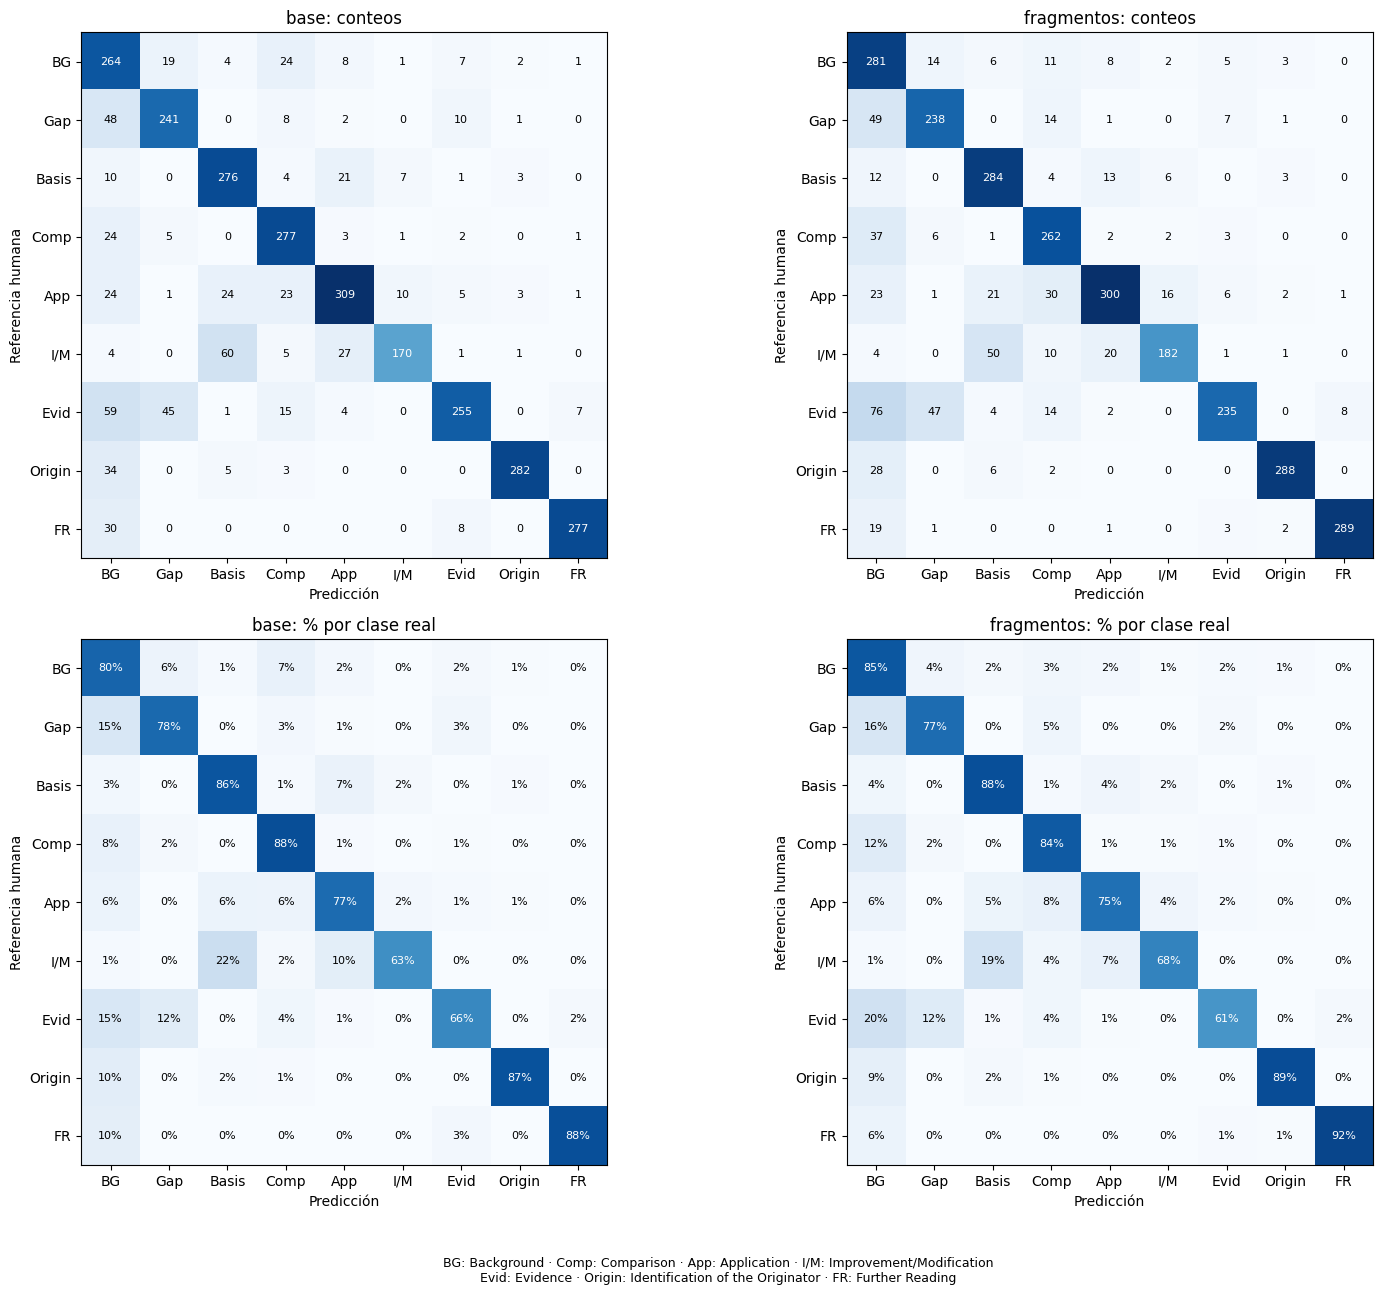

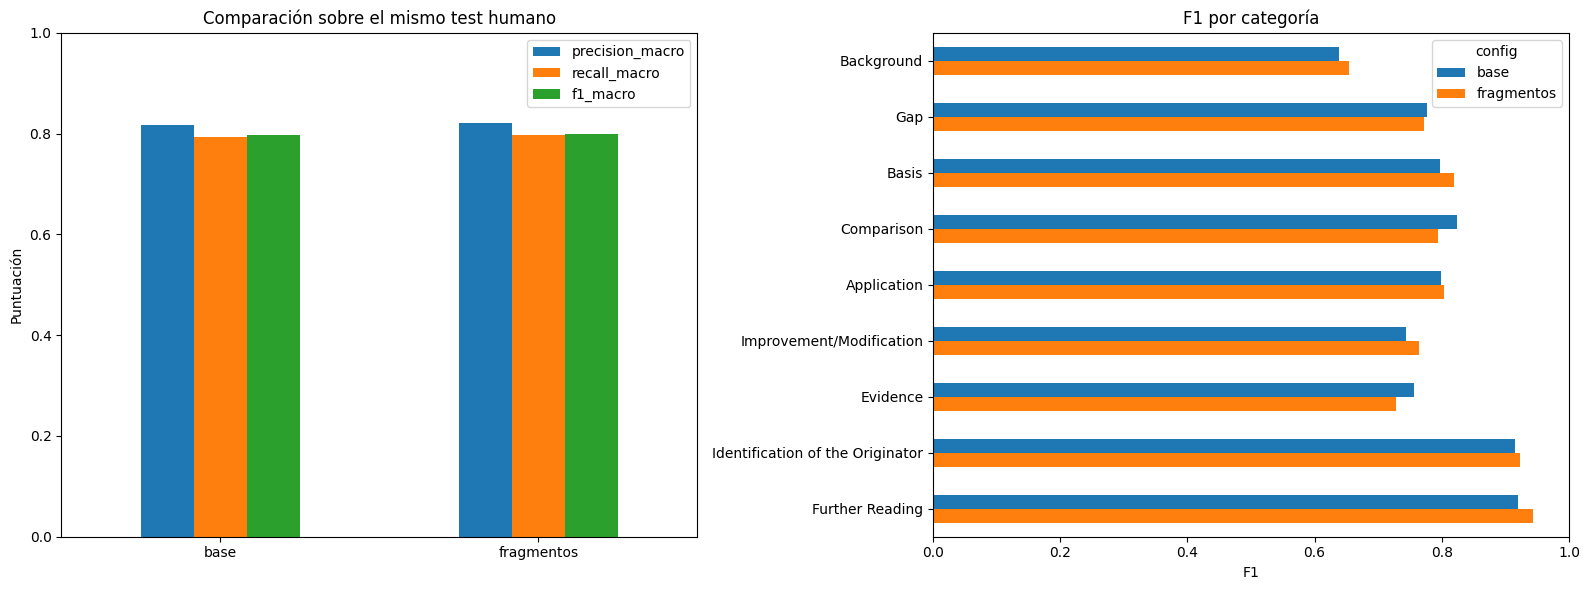

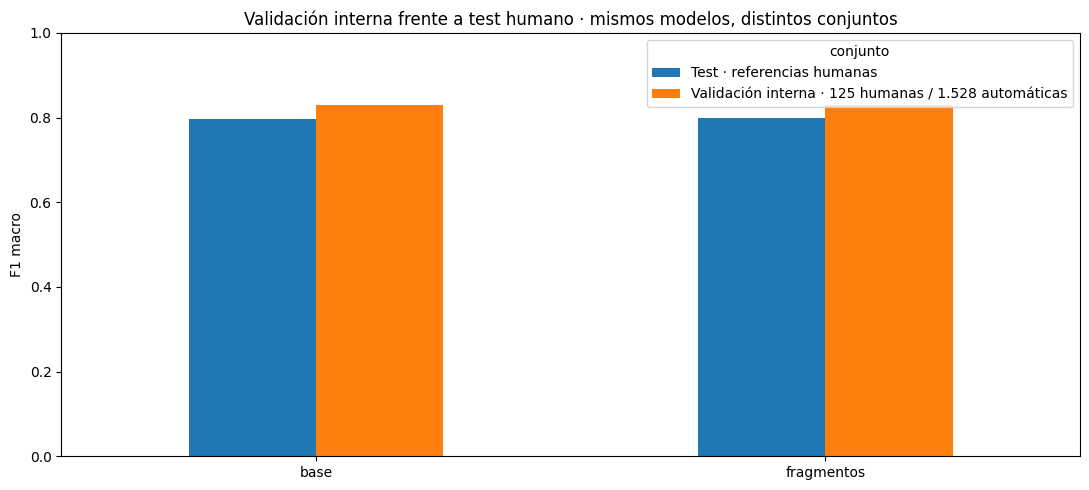

La diferencia entre conjuntos no demuestra una mejora o deterioro del modelo: cambian las citas y sus referencias.


In [7]:
test_results,test_reports = build_reports(predictions,test_rows,train_rows,validation_results,PINS["labels"],OUTPUT_ROOT)


## 8. Comparamos la diferencia y revisamos errores reales

Estimamos la diferencia de F1 macro Top-3 menos base con 2.000 remuestreos pareados
por artículo citante: las citas del mismo artículo viajan juntas. Mostramos el
intervalo percentil del 95 %, conservando las nueve categorías en el cálculo.

Después mostramos dos errores reales asociados a confusiones frecuentes. Su selección
es reproducible y no cambia ningún modelo. Los textos sirven para revisar las causas;
no inventamos explicaciones a partir de una etiqueta equivocada.


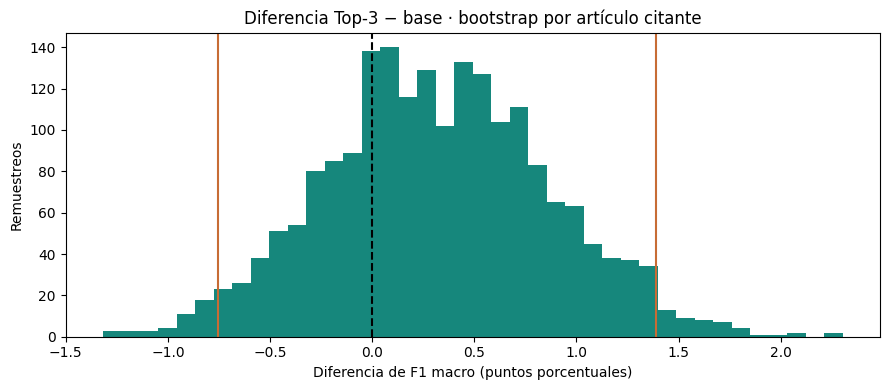

,inst_key,reference,base_prediction,top3_prediction,disagree,frequent_confusion,confusion_count_across_models,context_excerpt
0,1411.6067|10|260-309|1311.2524,Evidence,Background,Background,False,Evidence → Background,135,"Recently, CNNs [CITE], [CITE] have been shown ..."
1,1604.03227|2|102-151|1505.04366,Improvement/Modification,Basis,Basis,False,Improvement/Modification → Basis,110,Inspired by the success of convolutional-decon...


,difference,metric,delta,ci95_percentile,bootstrap_unit,n_groups,n_instances,repetitions,seed,fixed_labels
0,Top-3 minus base,f1_macro,0.003223,"[-0.007535624220191684, 0.013895142454058197]",citing_paper_id,2764,2968,2000,20261113,"[Background, Gap, Basis, Comparison, Applicati..."


Los ejemplos muestran errores reales frecuentes. Sus causas requieren lectura; no se asignan explicaciones automáticas.


In [8]:
paired = show_paired_and_errors(predictions,PINS["labels"],texts,OUTPUT_ROOT,
    PROTOCOL["bootstrap"]["repetitions"],PROTOCOL["bootstrap"]["seed"])


## 9. Conclusiones de la evaluación final

Evaluamos los dos modelos congelados sobre **2,968 citas con referencia humana**. Base obtuvo F1 macro **0.7967** y micro **0.7921**; Top-3 obtuvo **0.8000** y **0.7948**, respectivamente. La diferencia Top-3 − base fue **+0.32 puntos porcentuales**, con IC 95 % por bootstrap pareado por artículo citante **[-0.75; +1.39]**. El intervalo incluye cero; no establece una ventaja clara de una entrada sobre la otra.

En Improvement/Modification, con 268 ejemplos de test, el F1 fue **0.7440** para base y **0.7647** para Top-3. Las matrices y los reportes permiten distinguir las confusiones por categoría. Esta clase tuvo solo 140 ejemplos de entrenamiento; su resultado no elimina la limitación de representación.

Los mismos modelos habían obtenido F1 macro de validación interna 0.8303 y 0.8301. Esa validación tenía 125 etiquetas humanas y 1.528 automáticas: la diferencia con el test no demuestra por sí sola una mejora o deterioro. Conservamos los modelos, el recorte a 512 tokens y la separación por documento; el test no se utilizó para ajustar parámetros. Los resultados se limitan al conjunto evaluado y sus criterios de selección.


In [9]:
conclusion_text = final_conclusions(test_results,test_reports,paired,validation_results)
(OUTPUT_ROOT/"conclusiones.md").write_text(conclusion_text,encoding="utf-8")
report_hashes = {}
for path in OUTPUT_ROOT.rglob("*"):
    if path.is_file() and "_tracking" not in path.relative_to(OUTPUT_ROOT).parts and path.name!="FINAL_COMPLETE.json" and ".partial" not in path.name:
        report_hashes[path.relative_to(OUTPUT_ROOT).as_posix()]=sha256(path)
save_json(OUTPUT_ROOT/"FINAL_COMPLETE.json",{"run_id":RUN_ID,"protocol_sha256":json_digest(PROTOCOL),
    "n_test":len(test_rows),"test_scored":True,"model_trials":{c:m["trial_id"] for c,m in PINS["models"].items()},
    "metrics":test_results,"paired_test_comparison":paired,"report_hashes":report_hashes})
for config in predictions:
    parent=tracking.parent(config)
    tracking.metrics(parent,{f"test_{k}":v for k,v in test_results[config].items()})
    for name in ["evaluation_protocol.json","environment.json","test_comparison.csv","test_per_class.csv",
                 "validation_vs_test.csv","paired_test_comparison.json","conclusiones.md","FINAL_COMPLETE.json",
                 "test_confusion_comparison.png","test_metrics_comparison.png","validation_vs_test.png"]:
        tracking.client.log_artifact(parent,str(OUTPUT_ROOT/name),artifact_path="final_test")
    tracking.client.set_terminated(parent,"FINISHED")
tracking.backup(force=True)
release_experiment_writer(TRACKING_ROOT)
display(Markdown(conclusion_text))
print("Evaluación final cerrada y respaldada:",OUTPUT_ROOT)


MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_test_B_final_01/_tracking/snapshots/20261113T211318096884Z_0ff99e6a


Evaluamos los dos modelos congelados sobre **2,968 citas con referencia humana**. Base obtuvo F1 macro **0.7967** y micro **0.7921**; Top-3 obtuvo **0.8000** y **0.7948**, respectivamente. La diferencia Top-3 − base fue **+0.32 puntos porcentuales**, con IC 95 % por bootstrap pareado por artículo citante **[-0.75; +1.39]**. El intervalo incluye cero; no establece una ventaja clara de una entrada sobre la otra.

En Improvement/Modification, con 268 ejemplos de test, el F1 fue **0.7440** para base y **0.7647** para Top-3. Las matrices y los reportes permiten distinguir las confusiones por categoría. Esta clase tuvo solo 140 ejemplos de entrenamiento; su resultado no elimina la limitación de representación.

Los mismos modelos habían obtenido F1 macro de validación interna 0.8303 y 0.8301. Esa validación tenía 125 etiquetas humanas y 1.528 automáticas: la diferencia con el test no demuestra por sí sola una mejora o deterioro. Conservamos los modelos, el recorte a 512 tokens y la separación por documento; el test no se utilizó para ajustar parámetros. Los resultados se limitan al conjunto evaluado y sus criterios de selección.


Evaluación final cerrada y respaldada: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_test_B_final_01
